In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler

from KRR_utils import *
from nystrom_functions import *

CT Slice Localization:

In [8]:
df = pd.read_csv("../Data/slice_localization_data.csv")

X = df.iloc[:, 1:-1].to_numpy(dtype=float)
y = df.iloc[:, -1].to_numpy(dtype=float)

print(X.shape)
print(y.shape)

(53500, 384)
(53500,)


In [9]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

rng = np.random.default_rng()

gamma = 1/X_scaled.shape[1]

def rbf2(A, B):
    K = rbf(A, B, gamma=gamma)
    return K

In [26]:
# MSE and lambda plot

train_size = 800
test_size = 200
perm = rng.permutation(X_scaled.shape[0])
train_ind = perm[:train_size]
test_ind = perm[train_size:train_size + test_size]
X_train = X_scaled[train_ind]
y_train = y[train_ind]
X_test = X_scaled[test_ind]
y_test = y[test_ind]
lambdas = np.logspace(-5, 3, 9)
mse_rows = []
K_train = make_kernel_matrix(X_train, rbf2)
K_test = rbf2(X_test, X_train)

for lam in lambdas:
    alpha = np.linalg.solve(K_train + lam*np.eye(train_size), y_train)
    pred = K_test @ alpha
    mse = np.mean((pred - y_test)**2)
    mse_rows.append([lam, mse])

mse_df = pd.DataFrame(mse_rows, columns=["lambda", "test_mse"])
mse_df.to_csv("../Results/CTSliceLocalization_mse_vs_lambda.csv", index=False)
mse_df

,lambda,test_mse
0,0.00001,34.885844
1,0.00010,34.892916
2,0.00100,34.948188
3,0.01000,35.205833
4,0.10000,37.554351
5,1.00000,64.840336
6,10.00000,178.596682
7,100.00000,623.240849
8,1000.00000,2131.663168


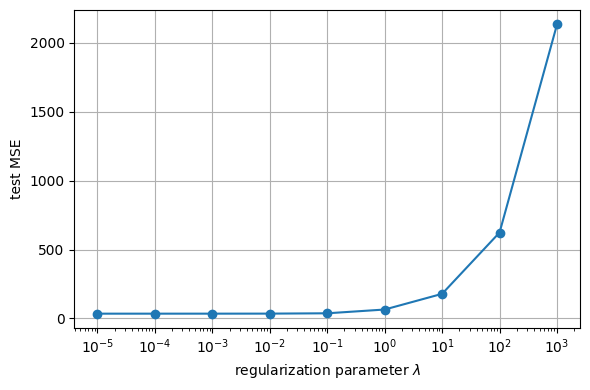

In [27]:
# Plot MSE against lambda

plt.figure(figsize=(6, 4))
plt.semilogx(mse_df["lambda"], mse_df["test_mse"], marker="o")
plt.xlabel("regularization parameter $\lambda$")
plt.ylabel("test MSE")
plt.grid(True)
plt.tight_layout()
plt.savefig("../Results/CTSliceLocalization_mse_vs_lambda.pdf")
plt.show()

In [28]:
from sklearn.linear_model import Ridge

# linear ridge regression

linear_rows = []

for lam in lambdas:
    model = Ridge(alpha=lam)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    mse = np.mean((pred - y_test)**2)
    linear_rows.append([lam, mse])

linear_df = pd.DataFrame(linear_rows, columns=["lambda", "test_mse"])
linear_df

,lambda,test_mse
0,0.00001,132.905046
1,0.00010,132.903236
2,0.00100,132.885138
3,0.01000,132.705431
4,0.10000,131.025431
5,1.00000,120.719228
6,10.00000,96.827362
7,100.00000,75.972230
8,1000.00000,81.822940


In [29]:
# compare linear ridge and RBF KRR

linear_mse = linear_df["test_mse"].min()
rbf_mse = mse_df["test_mse"].min()
mean_pred = np.full(test_size, np.mean(y_train))
mean_mse = np.mean((mean_pred - y_test)**2)
linear_r2 = 1 - linear_mse / mean_mse
rbf_r2 = 1 - rbf_mse / mean_mse
linear_rmse = np.sqrt(linear_mse)
rbf_rmse = np.sqrt(rbf_mse)
relative_excess_rmse = (linear_rmse - rbf_rmse) / rbf_rmse

print("best linear MSE:", linear_mse)
print("best RBF KRR MSE:", rbf_mse)
print("linear R squared:", linear_r2)
print("RBF R squared:", rbf_r2)
print("relative excess linear RMSE:", relative_excess_rmse)

best linear MSE: 75.97223041072294
best RBF KRR MSE: 34.88584369491728
linear R squared: 0.8453863934575603
RBF R squared: 0.9290026621334302
relative excess linear RMSE: 0.47571612585544243
